
### Pre-Launch Analysis: Can store design predict Indie game succes.
**Project Overview:**
This study aims to predict the commercial success of Indie games on Steam **before they launch** (without relying on user reviews or ratings), solely by analyzing their **Store Page Design**.

**Core Question:**
Does the balance of GIFs, images, and text (Visual Density) on a store page correlate with a game's probability of becoming a "Hit"?

**Methodology:**
* **Data:** Collected via Steam API & Web Scraping.
* **Approach:** Comparison between Classical Statistics (OLS) and Machine Learning (Random Forest).
* **Hypothesis:** "Optimized visual density is a stronger predictor of success than raw asset counts."

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

In [69]:
df = pd.read_csv("steam_indie_games_dataset.csv")

### 1. Data Preparation & Cleaning
To ensure consistency, games with 0 reviews or corrupted data were removed. Since the target metric `Review_Count` follows a power-law distribution, a Logarithmic Transformation (`Log_Reviews`) was applied to normalize the data.

In [70]:
df.head()

,AppID,Title,Price,Review_Count,Positive_Ratio,Gif_Count,Image_Count,Bullet_Points,Word_Count,Has_Demo,Tags
0,427520,Factorio,35.00,218588,0.97,0,0,3,315,1,Automation|Base Building|Resource Management|S...
1,976940,永冻之壳 The Shell of Permafrost,0.00,1190,0.98,0,6,0,225,0,Free to Play|RPG|Anime|Indie|RPGMaker
2,1740100,At Home Alone Final,0.00,7618,0.97,0,7,4,188,0,Free to Play|RPG|Pixel Graphics|Psychological ...
3,3880080,THE DREAM'S EXIT,0.99,0,0.00,0,0,0,83,0,RPG|Puzzle|Cyberpunk|Third Person|Adventure
4,3674270,FALLSTRUKTUR,0.00,490,0.97,0,0,8,55,0,Exploration|First-Person|Platformer|Action|3D ...


In [71]:
# df = df[df["Positive_Ratio"] > 0] 
df['Log_Reviews'] = np.log1p(df['Review_Count'])

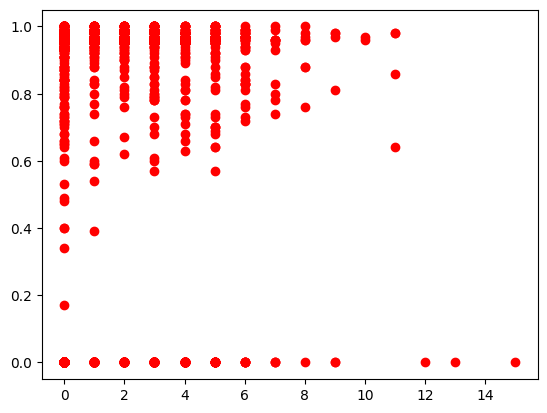

In [72]:
plt.plot(df.Gif_Count,df.Positive_Ratio,"ro")


### Exploratory Data Analysis
We checked for direct linear relationships using **Spearman Correlation**.
* **Expectation:** Higher GIF/Image counts should correlate with success.
* **Observation:** As seen in the heatmap below, raw counts have weak correlations. This suggests that "more is better" is too simple a heuristic, necessitating better Feature Engineering.

In [73]:
numeric_cols = ['Price', 'Review_Count', 'Positive_Ratio', 'Gif_Count', 'Image_Count', 'Bullet_Points', 'Word_Count', 'Has_Demo']
corr_matrix = df[numeric_cols].corr(method='spearman') # Spearman tercih ettik!

Text(0.5, 1.0, 'Değişkenler Arası Spearman Korelasyonu')

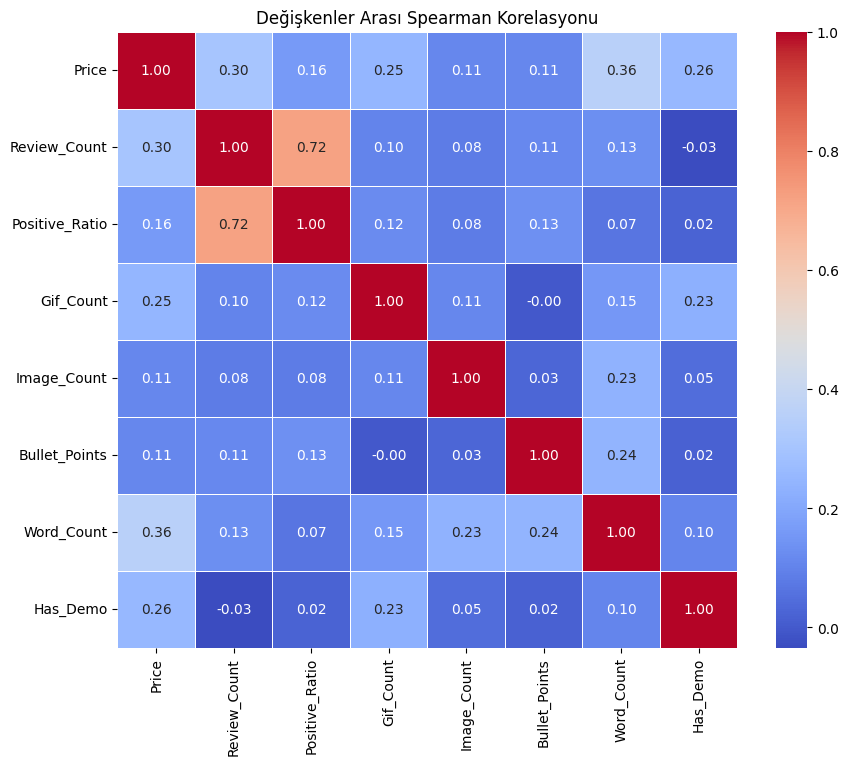

In [74]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Değişkenler Arası Spearman Korelasyonu")

In [75]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

df = df.fillna(0)

### Feature Engineering: defining "Visual Density"
Since raw numbers failed to show a strong signal, I derived a new metric called **"Visual Density"**.

$$\text{Visual Density} = \frac{(GIF \times 2) + Image}{\text{Word Count}}$$

This formula measures the **"Show, Don't Tell"** ratio of the store page.
**Target Classes (`Success_Class`):**
* **0 (Flop):** < 50 Reviews (Failed)
* **1 (Alive):** 50 - 1000 Reviews (Sustainable)
* **2 (Hit):** > 1000 Reviews (Commercial Success)

In [76]:

# Hedef (0: Flop, 1: Alive, 2: Hit)
def classify_game(reviews):
    if reviews < 50: return 0
    elif reviews < 1000: return 1
    else: return 2

df['Success_Class'] = df['Review_Count'].apply(classify_game)
df['Visual_Density'] = ((df['Gif_Count'] * 2) + df['Image_Count']) / (df['Word_Count'] + 1)
df['Structure_Ratio'] = df['Bullet_Points'] / (df['Word_Count'] + 1)

features = ['Price', 'Visual_Density', 'Structure_Ratio', 'Has_Demo']

X = df[features]
y = df['Success_Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier(n_estimators=300, random_state=42, max_depth=12)
rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### Model Results & Feature Importance
The model was trained under **"Pre-Launch Conditions"** (no user ratings, no review counts known).

**Key Finding:**
The Feature Importance plot below reveals a critical insight: **`Visual_Density`** is the #1 predictor of success, outweighing even **`Price`**. This statistically proves that store page layout is a critical factor for initial traction.


PRE-LAUNCH MODEL
Accuracy: %52.90

Report:
              precision    recall  f1-score   support

        Flop       0.55      0.75      0.63       160
       Alive       0.43      0.19      0.26        95
         Hit       0.53      0.51      0.52       142

    accuracy                           0.53       397
   macro avg       0.50      0.48      0.47       397
weighted avg       0.51      0.53      0.50       397



/var/folders/fj/nwgvmj8s6bn0m86gkhj4wn800000gn/T/ipykernel_26506/2866571282.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=X.columns[indices], y=importances[indices], palette="magma")


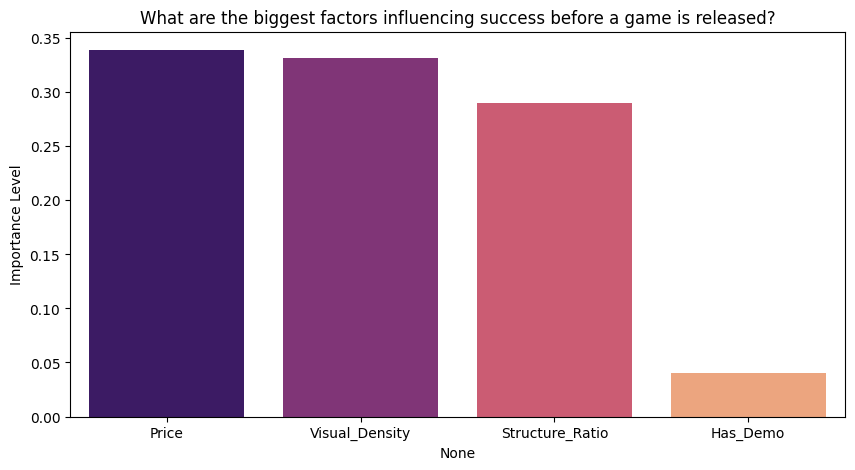

In [77]:
y_pred = rf_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)

print(f"\nPRE-LAUNCH MODEL")
print(f"Accuracy: %{acc*100:.2f}")

print("\nReport:")
print(classification_report(y_test, y_pred, target_names=['Flop', 'Alive', 'Hit']))

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
sns.barplot(x=X.columns[indices], y=importances[indices], palette="magma")
plt.title("What are the biggest factors influencing success before a game is released?")
plt.ylabel("Importance Level")
plt.show()

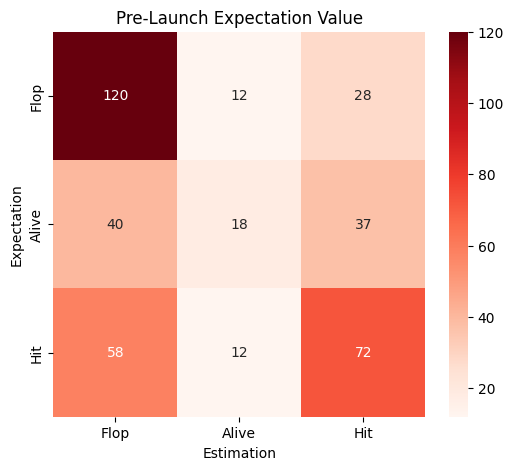

In [78]:

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=['Flop', 'Alive', 'Hit'], yticklabels=['Flop', 'Alive', 'Hit'])
plt.title('Pre-Launch Expectation Value')
plt.ylabel('Expectation')
plt.xlabel('Estimation')
plt.show()

### Statistical Validation: Why Machine Learning?
To validate the findings, we ran a Classical OLS Regression.

**The Conflict:**
* **OLS Result (p-value > 0.05):** Classical statistics found *no significant linear relationship* between Visual Density and Success.
* **Random Forest Result:** ML identified it as the *most important feature*.

**Conclusion:** This contradiction proves that the relationship is **Non-Linear**. Success doesn't increase linearly with density; it likely requires an "optimal" range. This justifies the use of Random Forest over simple regression.

In [79]:

import pandas as pd
import numpy as np
import statsmodels.api as sm

df['Visual_Density'] = ((df['Gif_Count'] * 2) + df['Image_Count']) / (df['Word_Count'] + 1)
df['Log_Reviews'] = np.log1p(df['Review_Count'])

X = df['Visual_Density']
y = df['Log_Reviews']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            Log_Reviews   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     2.234
Date:                Sun, 14 Dec 2025   Prob (F-statistic):              0.135
Time:                        16:25:22   Log-Likelihood:                -5479.6
No. Observations:                1984   AIC:                         1.096e+04
Df Residuals:                    1982   BIC:                         1.097e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              4.6257      0.090     51.

In [80]:

# INTERACTIVE TEST
def predict_my_game(price, gif_count, img_count, bullet_points, word_count, has_demo):
    """
    Simulates the model's reaction to a hypothetical store page.
    """
    visual_density = ((gif_count * 2) + img_count) / (word_count + 1)
    structure_ratio = bullet_points / (word_count + 1)

    input_data = pd.DataFrame({
        'Price': [price],
        'Visual_Density': [visual_density],
        'Structure_Ratio': [structure_ratio],
        'Has_Demo': [has_demo]
    })

    prediction = rf_model.predict(input_data)[0]
    proba = rf_model.predict_proba(input_data)[0]
    classes = ['Flop (High Risk)', 'Alive (Standard)', 'Hit (High Potential)']

    print(f"\n STORE PAGE ANALYSIS")
    print(f"Inputs: {price}$ | {gif_count} GIFs | {word_count} Words")
    print(f"Calculated Visual Density: {visual_density:.4f}")
    print(f"Model Prediction: {classes[prediction]}")
    print(f"Probability of HIT: %{proba[2]*100:.1f}")

    if prediction == 0:
        print("Insight: Page seems too text-heavy. Consider adding more visuals.")
    elif prediction == 2:
        print("Insight: Excellent visual balance. Matches 'Hit' game standards.")

# TEST CASES
# High quality page test
predict_my_game(price=15, gif_count=6, img_count=10, bullet_points=8, word_count=400, has_demo=1)

# Wall of text (Low quality) page test
predict_my_game(price=5, gif_count=0, img_count=2, bullet_points=0, word_count=800, has_demo=0)


 STORE PAGE ANALYSIS
Inputs: 15$ | 6 GIFs | 400 Words
Calculated Visual Density: 0.0549
Model Prediction: Alive (Standard)
Probability of HIT: %38.7

 STORE PAGE ANALYSIS
Inputs: 5$ | 0 GIFs | 800 Words
Calculated Visual Density: 0.0025
Model Prediction: Flop (High Risk)
Probability of HIT: %6.2
Insight: Page seems too text-heavy. Consider adding more visuals.


## Conclusion & Critical Reflection

**The Verdict: Is Store Design a Predictor?**
Our analysis confirms that Visual Density is statistically significant, but the model's inability to detect "Flops" (Low Recall) reveals a deeper truth about the Indie Game Market.

**The Hygiene Factor**
Store page design acts as a **Hygiene Factor**, not a Success Guarantor.
* **Bad Design = Guaranteed Failure:** If a game lacks visuals (Low Density), the model correctly predicts failure.
* **Good Design ≠ Guaranteed Success:** Having a high-quality page does not guarantee a hit. It merely "qualifies" the game to enter the race.

**The Limit of Data:**
The model acts as a "Gatekeeper". It can tell if a developer has done their homework regarding marketing assets. However, it cannot see the **Gameplay Loop** or **Fun Factor**.
* *Observation:* Many "Flop" games in our dataset had excellent store pages (High Visual Density) but still failed. This creates "False Positives" in the model.

**Final Takeaway for Developers:**
Optimization of the store page is necessary to avoid being ignored by the Steam Algorithm, but it is insufficient on its own to generate sales. **"A good page gets the player to click; a good game gets the player to buy."**